# TP5 · Ej. 2 — Propuesta B: VAE sobre **estados cuánticos de 10 qubits** (MNISQ)
*(Propuesta alternativa; el `ejercicio2.ipynb` original no se modifica. Tema ligado a *Introducción a la Computación Cuántica*, UNC.)*

**Dataset (GitHub):** [FujiiLabCollaboration/MNISQ-quantum-circuit-dataset](https://github.com/FujiiLabCollaboration/MNISQ-quantum-circuit-dataset) (Placidi et al. 2023, arXiv:2306.16627): **circuitos cuánticos reales** (QASM, 10 qubits) que preparan, desde |0…0⟩, un estado cuyas amplitudes codifican una imagen (MNIST / Fashion-MNIST / Kuzushiji). Cada muestra trae el **vector de estado** |ψ⟩ ∈ ℂ¹⁰²⁴, el circuito, la etiqueta y la fidelidad de la preparación. Hay 10 000 (test) a 60 000 (train, ~500 MB) por subconjunto, y 480 000 aumentados.

**Pregunta:** ¿un VAE puede aprender la **variedad de estados cuánticos** que representan dígitos y generar *nuevos estados válidos*? Los criterios de "pertenece al conjunto" son ahora cuánticos y exactos:
1. **Normalización** ‖ψ‖ = 1 (la decodificación normaliza; la pérdida usa la **infidelidad** 1 − |⟨ψ|φ⟩|²).
2. **Fidelidad** media de reconstrucción y fidelidad máxima con el conjunto real (¿es un estado nuevo o una copia?).
3. **Entrelazamiento**: entropía de von Neumann del corte 5|5 qubits, real vs. generado.
4. **Medición (regla de Born)**: |ψᵢ|² como distribución de probabilidad; se simulan *shots*.
5. Distancia de Fréchet en el espacio de un clasificador juez (como en el ej2 original).

> Colab: GPU opcional (~5 min con el subconjunto de test).

In [1]:
RAPIDO = False
SEED   = 0
TIPO   = 'mnist_784'       # 'mnist_784' | 'Fashion-MNIST' | 'Kuzushiji-MNIST'
FID    = 'f90'             # f80 | f90 | f95 (fidelidad mínima del circuito)
PARTE  = 'test'            # 'test' (10 000, ~80 MB)  |  'train_orig' (60 000, ~500 MB)
D_LAT  = 16
EPOCAS = 40 if not RAPIDO else 4
import os, io, zipfile, urllib.request, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from scipy import linalg
np.random.seed(SEED); torch.manual_seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'; print('dispositivo:', dev)

dispositivo: cuda


In [2]:
# ---- Descarga de MNISQ (S3 público del repositorio) y carga de estados ----------------------------
nombre = f'base_{PARTE}_{TIPO}_{FID}'
url = f'https://qulacs-quantum-datasets.s3.us-west-1.amazonaws.com/{nombre}.zip'
if not os.path.exists(nombre + '.zip'):
    print('descargando', url); urllib.request.urlretrieve(url, nombre + '.zip')
Z = zipfile.ZipFile(nombre + '.zip')
ids = sorted({n.split('/')[-1] for n in Z.namelist() if '/state/' in n and not n.endswith('/')}, key=int)
if RAPIDO: ids = ids[:2000]
def leer_estado(i):
    a = np.loadtxt(io.StringIO(Z.read(f'{nombre}/state/{i}').decode())); return (a[:,0] + 1j*a[:,1])
PSI = np.stack([leer_estado(i) for i in ids]); Y = np.array([int(Z.read(f'{nombre}/label/{i}').decode()) for i in ids])
FIDEL = np.array([float(Z.read(f'{nombre}/fidelity/{i}').decode().split()[0]) for i in ids])
print('estados:', PSI.shape, '| parte imaginaria máx:', np.abs(PSI.imag).max(), '| norma media:', np.linalg.norm(PSI,axis=1).mean().round(6))
print('fidelidad de preparación media:', FIDEL.mean().round(3), '| etiquetas:', np.bincount(Y))

descargando https://qulacs-quantum-datasets.s3.us-west-1.amazonaws.com/base_test_mnist_784_f90.zip
estados: (10000, 1024) | parte imaginaria máx: 0.0 | norma media: 1.0
fidelidad de preparación media: 0.924 | etiquetas: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


## 1. Qué hay dentro de un estado
Las amplitudes (reales, ≥ 0 en su mayoría) de las primeras 784 posiciones son los píxeles normalizados; las 240 restantes son 0 (relleno hasta 2¹⁰). Se muestran el estado como imagen 28×28, la distribución de Born |ψᵢ|² y el circuito QASM (primeras líneas).

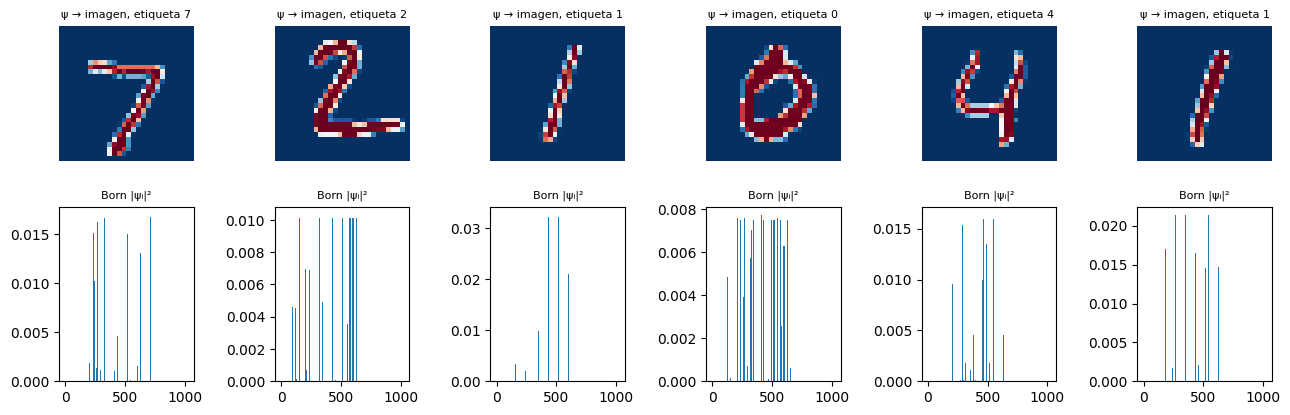

OPENQASM 2.0;
include "qelib1.inc";
qreg q[10];
x q[0];
x q[1];
x q[5];
x q[6];
x q[8];
u(1.5707963267948966,-1.5645959742720543,-1.5707963267948966) q[0];
u(0.7168769581444515,-1.5707963267948966,-3.141592653589793) q[5];
cx q[0],q[5];
u(1.6326388308505078,-3.141592653589793,1.5707963267948966) q[0];
u(1.0858143200525017,-0.5718323175968174,2.4220600878727883) q[5];
cx q[0],q[5];
u(1.5707963267948966,1.5707963267948966,3.1282947536278716) q[0];
u(0.8340471649609151,0,1.5707963267948966) q[5];
u(1.5086239381843163,-1.5707963267948966,0) q[1];
u(2.410911159988946,1.5084398885606003,1.5243314403 …


In [3]:
P = np.abs(PSI)**2
fig, ax = plt.subplots(2, 6, figsize=(13, 4.4))
for k in range(6):
    ax[0,k].imshow(PSI[k].real[:784].reshape(28,28), cmap='RdBu_r'); ax[0,k].set_title(f'ψ → imagen, etiqueta {Y[k]}', fontsize=8); ax[0,k].axis('off')
    ax[1,k].bar(range(1024), P[k], width=1.0); ax[1,k].set_title('Born |ψᵢ|²', fontsize=8)
plt.tight_layout(); plt.show()
print(Z.read(f'{nombre}/qasm/{ids[0]}').decode()[:600], '…')

entropia 5|5: media 2.89 máx posible 5 bits


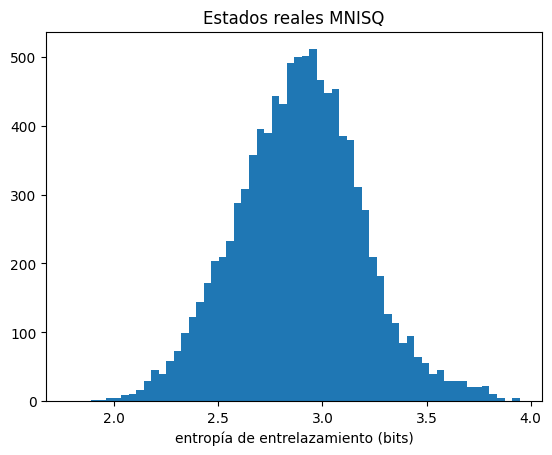

In [4]:
# Entrelazamiento: entropía de von Neumann del corte 5|5 (matriz 32x32 de amplitudes, valores singulares)
def entropia_5_5(psi):
    s = np.linalg.svd(psi.reshape(32,32), compute_uv=False)**2; s = s[s>1e-12]; return float(-(s*np.log2(s)).sum())
S_real = np.array([entropia_5_5(p) for p in PSI])
print('entropia 5|5: media', S_real.mean().round(3), 'máx posible 5 bits')
plt.hist(S_real, 60); plt.xlabel('entropía de entrelazamiento (bits)'); plt.title('Estados reales MNISQ'); plt.show()

## 2. VAE de estados con pérdida cuántica
Entrada: Re(ψ) (el dataset tiene parte imaginaria nula; se verifica arriba) → vector real unitario de 1024. Decodificador: MLP → vector → **normalización L2** (estado válido por construcción).
Pérdida = (1 − F) + β·KL/D, con F = |⟨ψ|φ⟩|² la fidelidad de reconstrucción. β = 0 es un autoencoder.

In [5]:
Xs = torch.tensor(PSI.real.astype(np.float32)); ys = torch.tensor(Y)
rng = np.random.default_rng(SEED); idx = rng.permutation(len(Xs)); ntr = int(.9*len(Xs)); tr, te = idx[:ntr], idx[ntr:]
class VAEq(nn.Module):
    def __init__(s, d=D_LAT, h=512):
        super().__init__()
        s.e = nn.Sequential(nn.Linear(1024,h),nn.ReLU(),nn.Linear(h,h//2),nn.ReLU()); s.mu, s.lv = nn.Linear(h//2,d), nn.Linear(h//2,d)
        s.d = nn.Sequential(nn.Linear(d,h//2),nn.ReLU(),nn.Linear(h//2,h),nn.ReLU(),nn.Linear(h,1024))
    def decode(s, z): return F.normalize(s.d(z), dim=1)             # |φ| = 1
    def forward(s, x):
        h = s.e(x); mu, lv = s.mu(h), s.lv(h); z = mu + torch.randn_like(mu)*torch.exp(.5*lv); return s.decode(z), mu, lv
def entrenar(beta, ep=EPOCAS, bs=256):
    torch.manual_seed(SEED); m = VAEq().to(dev); opt = torch.optim.Adam(m.parameters(), 1e-3); Xt = Xs[tr]
    for e in range(ep):
        perm = torch.randperm(len(Xt)); tot = 0
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i+bs]].to(dev); xr, mu, lv = m(xb)
            infid = (1 - (xr*xb).sum(1)**2).mean(); kl = (-.5*(1+lv-mu**2-lv.exp()).sum(1)).mean()/D_LAT
            l = infid + beta*kl; opt.zero_grad(); l.backward(); opt.step(); tot += l.item()*len(xb)
        if e % max(1, ep//4) == 0 or e == ep-1: print(f'  β={beta} época {e+1}/{ep} pérdida {tot/len(Xt):.4f}')
    return m.eval()
BETAS = [0.0, 0.01, 0.1]
modelos = {b: entrenar(b) for b in BETAS}

  β=0.0 época 1/40 pérdida 0.6340
  β=0.0 época 11/40 pérdida 0.2634
  β=0.0 época 21/40 pérdida 0.1864
  β=0.0 época 31/40 pérdida 0.1485
  β=0.0 época 40/40 pérdida 0.1304
  β=0.01 época 1/40 pérdida 0.6348
  β=0.01 época 11/40 pérdida 0.2650
  β=0.01 época 21/40 pérdida 0.2036
  β=0.01 época 31/40 pérdida 0.1760
  β=0.01 época 40/40 pérdida 0.1604
  β=0.1 época 1/40 pérdida 0.6350
  β=0.1 época 11/40 pérdida 0.3559
  β=0.1 época 21/40 pérdida 0.3126
  β=0.1 época 31/40 pérdida 0.2944
  β=0.1 época 40/40 pérdida 0.2849


## 3. Juez cuántico-clásico y métricas
* **Juez**: MLP que clasifica el dígito a partir del vector de estado; sus características (128-d) dan la distancia de Fréchet.
* **Fidelidad de reconstrucción** en test; **fidelidad máxima con el conjunto de entrenamiento** de las muestras del prior (¿nuevas o copias?); **entropía 5|5**; **dígito predicho**.

In [6]:
juez = nn.Sequential(nn.Linear(1024,256),nn.ReLU(),nn.Linear(256,128),nn.ReLU()).to(dev); cab = nn.Linear(128,10).to(dev)
opt = torch.optim.Adam(list(juez.parameters())+list(cab.parameters()), 1e-3)
for e in range(10 if not RAPIDO else 3):
    perm = torch.tensor(tr)[torch.randperm(len(tr))]
    for i in range(0,len(perm),256):
        b = perm[i:i+256]; l = F.cross_entropy(cab(juez(Xs[b].to(dev))), ys[b].to(dev)); opt.zero_grad(); l.backward(); opt.step()
with torch.no_grad(): print('exactitud del juez en test:', (cab(juez(Xs[te].to(dev))).argmax(1).cpu()==ys[te]).float().mean().item())
@torch.no_grad()
def feats(X): return juez(X.to(dev)).cpu().numpy().astype(np.float64)
def frechet(a,b):
    m1,m2=a.mean(0),b.mean(0); s1,s2=np.cov(a,rowvar=False),np.cov(b,rowvar=False); c=linalg.sqrtm(s1@s2); c=c.real if np.iscomplexobj(c) else c
    return float(((m1-m2)**2).sum()+np.trace(s1+s2-2*c))
Fte = feats(Xs[te]); piso = frechet(Fte[:len(Fte)//2], Fte[len(Fte)//2:]); print(f'piso Fréchet real↔real: {piso:.2f}')
Xtr_d = Xs[tr].to(dev); ns = 2000; filas = []; muestras = {}
for b, m in modelos.items():
    with torch.no_grad():
        xr = m(Xs[te].to(dev))[0].cpu(); fid_rec = ((xr*Xs[te]).sum(1)**2).mean().item()
        S = m.decode(torch.randn(ns, D_LAT, device=dev)); fmax = ((S@Xtr_d.T)**2).max(1).values.cpu()
        pred = cab(juez(S)).argmax(1).cpu().numpy(); S = S.cpu()
    muestras[b] = (S, pred)
    ent = np.array([entropia_5_5(s.numpy()) for s in S[:1000]])
    filas.append((b, round(fid_rec,4), round(float(fmax.mean()),4), round(frechet(feats(S), Fte),2), round(ent.mean(),3)))
import pandas as pd
print(pd.DataFrame(filas, columns=['β','fidelidad recon.','fidelidad máx. c/entrenamiento','Fréchet(prior)','entropía 5|5 media']).to_string(index=False))
print('entropía 5|5 real media:', S_real.mean().round(3))

exactitud del juez en test: 0.9330000281333923
piso Fréchet real↔real: 0.81


/tmp/ipykernel_3109/459111762.py:11: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  m1,m2=a.mean(0),b.mean(0); s1,s2=np.cov(a,rowvar=False),np.cov(b,rowvar=False); c=linalg.sqrtm(s1@s2); c=c.real if np.iscomplexobj(c) else c


   β  fidelidad recon.  fidelidad máx. c/entrenamiento  Fréchet(prior)  entropía 5|5 media
0.00            0.8519                          0.4376          216.41               3.018
0.01            0.8434                          0.6591          232.45               2.722
0.10            0.7694                          0.8040          247.12               2.527
entropía 5|5 real media: 2.89


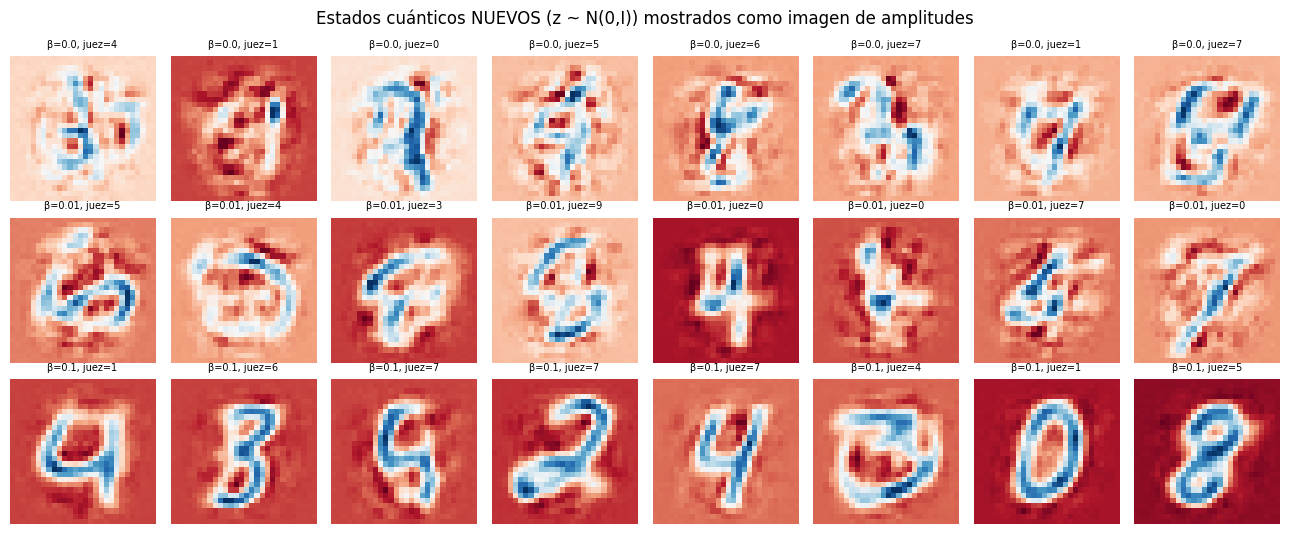

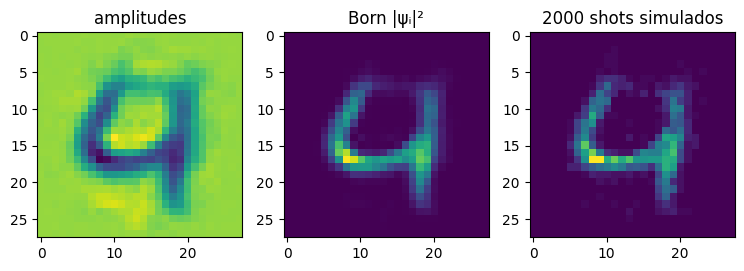

In [7]:
fig, ax = plt.subplots(len(BETAS), 8, figsize=(13, 1.8*len(BETAS)))
for r, b in enumerate(BETAS):
    S, pred = muestras[b]
    for c in range(8):
        ax[r,c].imshow(S[c].numpy()[:784].reshape(28,28), cmap='RdBu_r'); ax[r,c].axis('off'); ax[r,c].set_title(f'β={b}, juez={pred[c]}', fontsize=7)
plt.suptitle('Estados cuánticos NUEVOS (z ~ N(0,I)) mostrados como imagen de amplitudes'); plt.tight_layout(); plt.show()
# Regla de Born: simular 2000 shots de un estado generado y reconstruir la imagen desde los conteos
S, pred = muestras[BETAS[-1]]; p = S[0].numpy()**2; shots = np.random.default_rng(0).multinomial(2000, p/p.sum())
fig, ax = plt.subplots(1,3,figsize=(9,3)); ax[0].imshow(S[0].numpy()[:784].reshape(28,28)); ax[0].set_title('amplitudes')
ax[1].imshow(p[:784].reshape(28,28)); ax[1].set_title('Born |ψᵢ|²'); ax[2].imshow(shots[:784].reshape(28,28)); ax[2].set_title('2000 shots simulados'); plt.show()

## 4. Extensiones (para elegir)
* **Subconjunto con circuito**: el repositorio provee el QASM de cada estado; se puede ejecutar con Qiskit/PennyLane (`doc/source/notebooks/qiskit_quickstart.ipynb`) y comparar el estado de un circuito *real* con el estado generado por el VAE; o medir qué tan "preparable" es un estado generado (cuántas compuertas necesita).
* **Otros subconjuntos**: `Fashion-MNIST`, `Kuzushiji-MNIST` (cambiar `TIPO`), o el train aumentado (480 000).
* **VAE condicional** por dígito (generar "un 7 cuántico" nuevo).
* Citas: Placidi et al. (2023), *MNISQ*, arXiv:2306.16627; Nielsen & Chuang (2010) caps. 2 y 8; Kingma & Welling (2014); Higgins et al. (2017); Heusel et al. (2017).